# Docling - DocLayNet layout pipeline

In [1]:
from pathlib import Path
import json
import subprocess
import sys

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "methods").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "methods").is_dir():
    raise FileNotFoundError("Không tìm thấy thư mục gốc repository; hãy mở notebook từ project DO-AN-261.")

METHOD = "docling"
DATASET = "doclaynet"
SPLIT = "train"
IOU_THRESHOLD = 0.5
LIMIT = 0  # 0: toàn bộ ảnh trong tập dữ liệu; hoặc giới hạn số ảnh (vd: 20)
FORCE_INFERENCE = False  # True: chạy lại inference và ghi đè; False: bỏ qua ảnh đã có prediction
FIGURE_LIMIT = 20

PREDICTIONS_DIR = ROOT / "outputs" / "predictions" / METHOD / DATASET
FIGURES_DIR = ROOT / "outputs" / "reports" / f"{METHOD}_{DATASET}"
print(f"Project: {ROOT}")
print(f"Pipeline: {METHOD} | {DATASET}/{SPLIT} | IoU >= {IOU_THRESHOLD}")
print(f"Inference: {'force rerun' if FORCE_INFERENCE else 'skip existing predictions'}")
print(f"Predictions: {PREDICTIONS_DIR}")
print(f"Figures: {FIGURES_DIR}")


Project: D:\Semester_261\DoAnChuyenNganh\DO-AN-261
Pipeline: docling | doclaynet/train | IoU >= 0.5
Inference: skip existing predictions
Predictions: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\predictions\docling\doclaynet
Figures: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\reports\docling_doclaynet


## 1. Prediction

Inference processes local dataset images. Existing predictions are skipped by default; set `FORCE_INFERENCE = True` to overwrite them.

In [2]:
inference_script = ROOT / "methods" / METHOD / "src" / "run_inference.py"
command = [
    sys.executable,
    str(inference_script),
    "--dataset", DATASET,
    "--limit", str(LIMIT),
    "--force" if FORCE_INFERENCE else "--skip-existing",
]
print("Running:", " ".join(command))
res = subprocess.run(command, cwd=ROOT, capture_output=True, text=True, check=True)
print(res.stdout)
print(f"Predictions: {PREDICTIONS_DIR}")


Running: C:\Users\thien\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe D:\Semester_261\DoAnChuyenNganh\DO-AN-261\methods\docling\src\run_inference.py --dataset doclaynet --limit 0 --skip-existing


[docling] 0 image(s) to predict from D:\Semester_261\DoAnChuyenNganh\DO-AN-261\datasets\doclaynet\processed\images (existing predictions skipped)
[docling] No work to do. Predictions are in D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\predictions\docling\doclaynet

Predictions: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\predictions\docling\doclaynet


## 2. Metrics and Evaluation Chart

Đánh giá kết quả trên tập ảnh vừa thực thi inference (`outputs/predictions/docling/doclaynet/`).
- **Strict**: Yêu cầu khớp cả tọa độ (IoU >= threshold) và đúng nhãn.
- **Loose**: Chỉ đánh giá khả năng định vị (localization), bỏ qua nhãn.
- **Biểu đồ**: Trực quan hóa Precision, Recall, F1 theo từng class và so sánh Strict vs Loose.

Running evaluation:


Evaluation: docling on doclaynet/train | 1928 images | GT=24,229 boxes | Predictions=21,670 boxes | IoU >= 0.5

=== Strict (location and class) ===
Micro: Precision=0.869  Recall=0.778  F1=0.821  TP=18840 FP=2830 FN=5389  mean IoU=0.939
Macro (mean across 10 ground-truth classes): Precision=0.562  Recall=0.548  F1=0.554
Class                   GT    Pred     TP     FP     FN     Prec   Recall       F1
Text                 12606   12637  11338   1299   1268    0.897    0.899    0.898
Section-header        4451    4689   3852    837    599    0.821    0.865    0.843
Page-footer           1552       0      0      0   1552    0.000    0.000    0.000
Table                 1456    1422   1347     75    109    0.947    0.925    0.936
List-item             1432    1285   1079    206    353    0.840    0.753    0.794
Page-header           1141       0      0      0   1141    0.000    0.000    0.000
Picture               1111    1208    942    266    169    0.780    0.848    0.812
Caption       

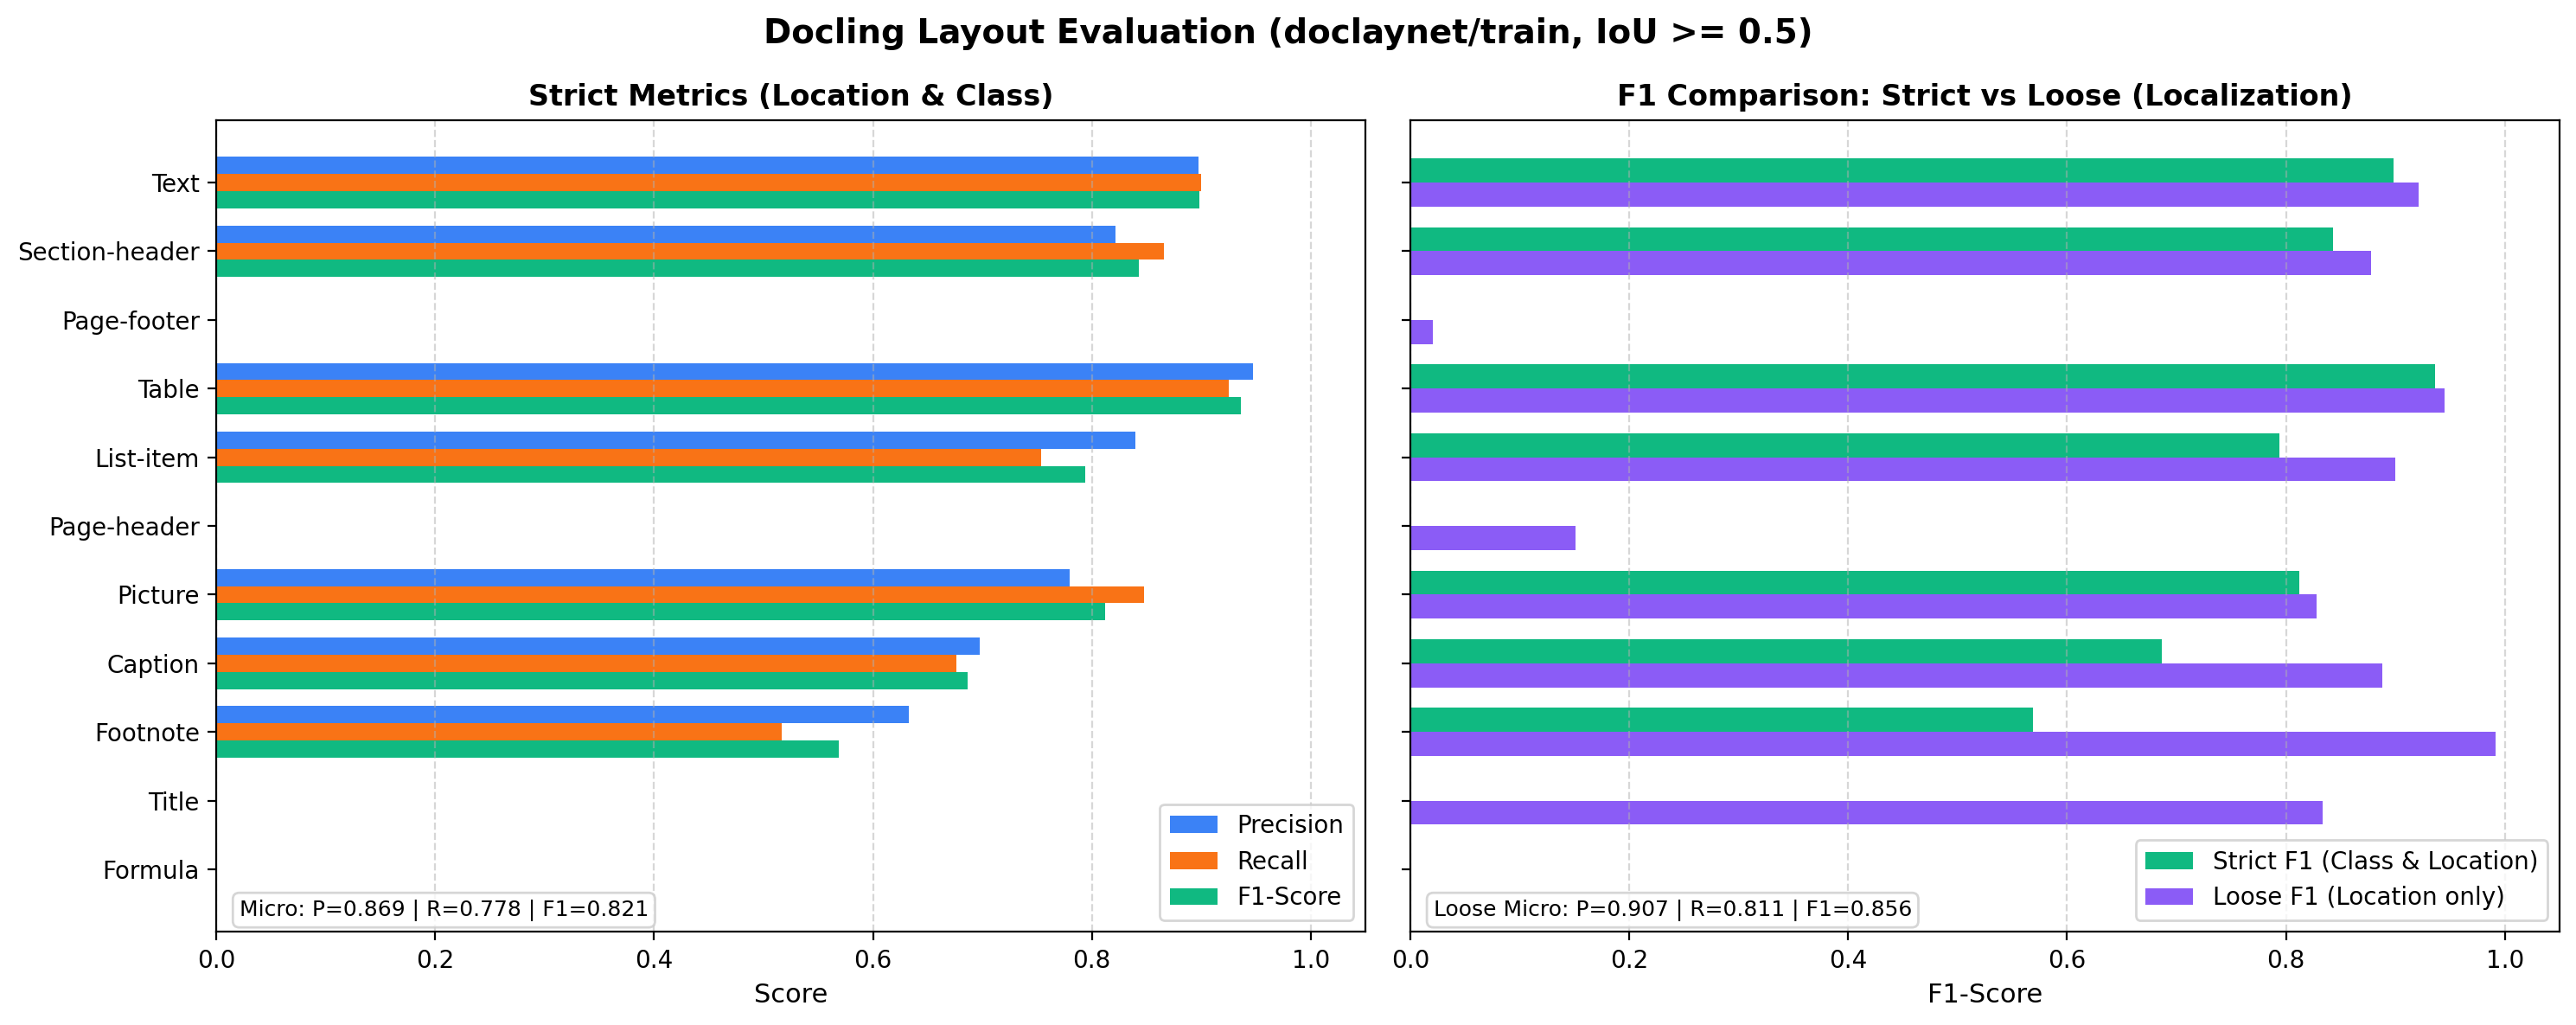

In [3]:
evaluation_script = ROOT / "scripts" / "evaluate_predictions.py"
command = [
    sys.executable,
    str(evaluation_script),
    "--method", METHOD,
    "--dataset", DATASET,
    "--split", SPLIT,
    "--iou-threshold", str(IOU_THRESHOLD),
    "--loose",
    "--plot", str(FIGURES_DIR / "metrics_chart.png"),
]
print("Running evaluation:")
res = subprocess.run(command, cwd=ROOT, capture_output=True, text=True, check=True)
print(res.stdout)

# Hiển thị biểu đồ đánh giá
chart_file = FIGURES_DIR / "metrics_chart.png"
if chart_file.is_file():
    from IPython.display import Image as DisplayImage, display
    print(f"Evaluation Chart ({chart_file}):")
    display(DisplayImage(filename=str(chart_file)))


## 3. Ground Truth vs. Prediction Examples

Trực quan hóa đối chiếu ảnh Ground Truth và kết quả dự đoán của Docling. Ảnh kết quả được lưu tại `outputs/reports/docling_doclaynet/`.

Running: C:\Users\thien\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe D:\Semester_261\DoAnChuyenNganh\DO-AN-261\visualization\scripts\visualize_predictions.py --method docling --dataset doclaynet --split train --limit 20 --output-dir D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\reports\docling_doclaynet


[viz] Ve 20 anh (docling vs ground truth) tu D:\Semester_261\DoAnChuyenNganh\DO-AN-261\visualization\scripts\..\..\outputs\predictions\docling\doclaynet
  [ok] 0.png
  [ok] 1.png
  [ok] 2.png
  [ok] 3.png
  [ok] 4.png
  [ok] 5.png
  [ok] 6.png
  [ok] 7.png
  [ok] 8.png
  [ok] 9.png
  [ok] 10.png
  [ok] 12.png
  [ok] 13.png
  [ok] 14.png
  [ok] 15.png
  [ok] 16.png
  [ok] 17.png
  [ok] 18.png
  [ok] 19.png
  [ok] 20.png
[viz] Xong. Anh luu tai D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\reports\docling_doclaynet

Ví dụ ảnh đối chiếu: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\reports\docling_doclaynet\0.png


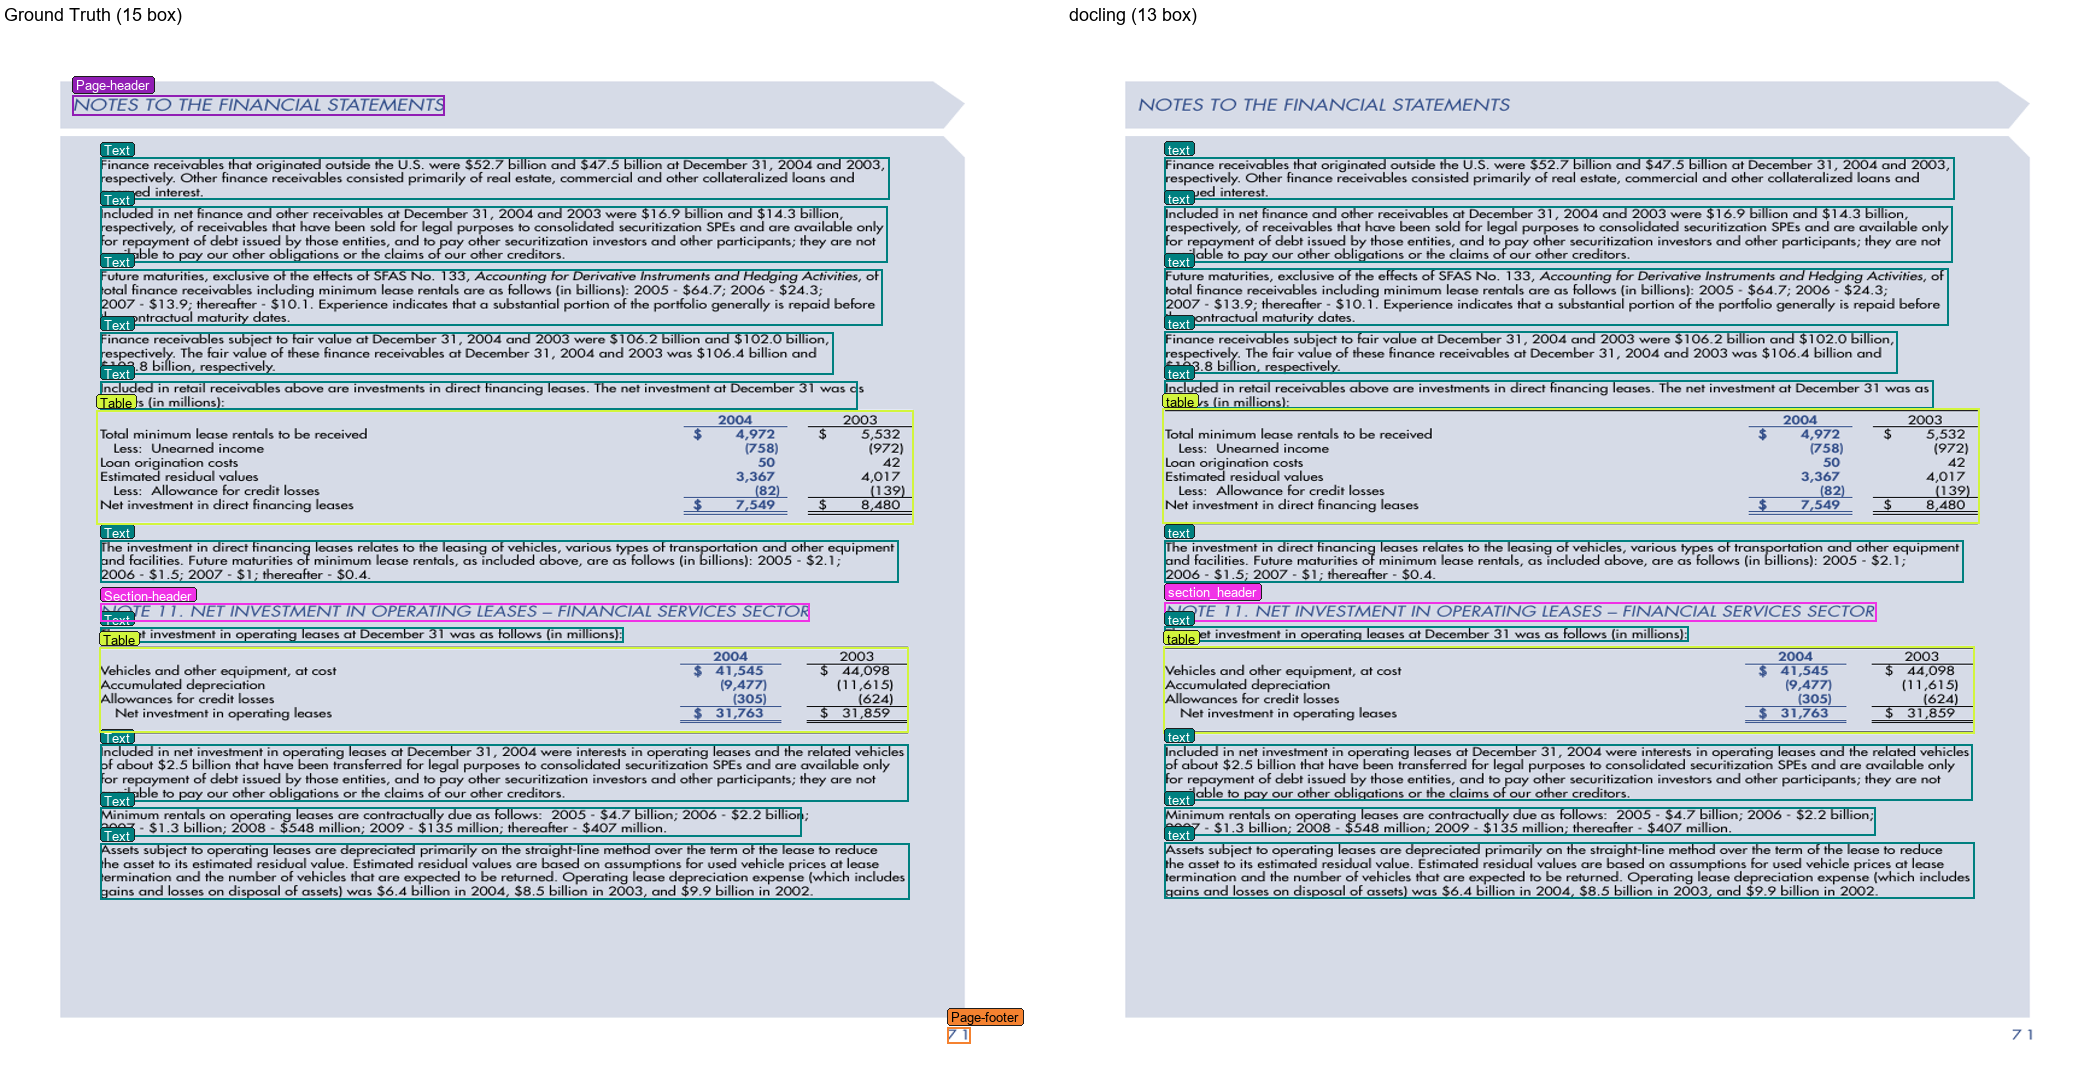

In [4]:
visualizer = ROOT / "visualization" / "scripts" / "visualize_predictions.py"
command = [
    sys.executable,
    str(visualizer),
    "--method", METHOD,
    "--dataset", DATASET,
    "--split", SPLIT,
    "--limit", str(FIGURE_LIMIT),
    "--output-dir", str(FIGURES_DIR),
]
print("Running:", " ".join(command))
res = subprocess.run(command, cwd=ROOT, capture_output=True, text=True, check=True)
print(res.stdout)

figure_files = sorted(
    FIGURES_DIR.glob("*.png"),
    key=lambda path: (0, int(path.stem)) if path.stem.isdigit() else (1, path.stem),
)
if figure_files:
    from IPython.display import Image as DisplayImage, display
    print(f"Ví dụ ảnh đối chiếu: {figure_files[0]}")
    display(DisplayImage(filename=str(figure_files[0])))
else:
    print(f"Không có hình ảnh nào trong {FIGURES_DIR}")


## Files đầu ra và báo cáo

- Predictions JSON: `outputs/predictions/docling/doclaynet/<image_id>.json`
- Ảnh đối chiếu trực quan: `outputs/reports/docling_doclaynet/<image_id>.png`
- Ground Truth COCO: `datasets/doclaynet/processed/annotations/train.json`